<p align="center">
    <img src="https://beyondeducation.es/wp-content/uploads/2024/02/CUNEF-UNI50.png" width="500">
</p>


<h1 align="center"><b>Initial Assignment - Machine Learning</b></h1>
<h2 align="center">M2026-27 - Master in Data Science and Artificial Intelligence</h2>

| Full name | CUNEF email |
|---|---|
| Melanie Álvarez | melanie.alvarez@cunef.edu |
| María Victoria del Campo | victoria.delcampo@cunef.edu |
| Alicia Plaza | alicia.plaza@cunef.edu |

**GitHub repository:** https://github.com/mvdelcampo/machine-learning-project

# **Data loading**

In [9]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("/Users/aliciaplaza/CUNEF/data")

bacteria_dataset = pd.read_csv(DATA_PATH / "Bacteria_dataset_Multiresictance.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


# **Exploratory Data Analysis**

## 1. Data description and inspection

In [10]:
bacteria_dataset.shape

(10710, 27)

In [11]:
bacteria_dataset.head()

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
0,S290,Elizabeth Lawrence,elizabeth.lawrence@example.com,"6350 Robinson Loaf Apt. 447, Paulfurt, RI 30252",37/F,S290 Escherichia coli,No,No,No,0.0,...,S,S,S,S,R,S,S,S,5 Fev 2025,Patient had fever??
1,S291,Tina Sanders,tina.sanders@example.com,"78594 Galloway Port Suite 762, South Tanyatown...",29/F,S291 Morganella morganii,True,No,No,3.0,...,S,S,S,S,S,S,S,S,08/05/2021,تم العلاج
2,S292,Erin Cooke,erin.cooke@example.com,"76661 Isaiah Manors, North Benjamin, HI 85195",77/F,S292 Proteus mirabilis,True,No,No,3.0,...,S,S,S,R,R,S,S,S,01/05/2022,NADA
3,S293,Mrs. Sharon Watson,mrs..sharon.watson@example.com,"1670 Thompson Way Apt. 520, Andrewbury, IL 11534",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO
4,S294,Erika Stewart,erika.stewart@example.com,"76838 Patrick Green Suite 538, Torresmouth, ME...",13/F,S294 Escherichia coli,No,Yes,No,1.0,...,R,S,S,S,S,S,S,S,error,NADA


In [12]:
inspection = pd.DataFrame({
    "dtype": bacteria_dataset.dtypes.astype(str),
    "non_null": bacteria_dataset.notna().sum(),
    "missing_pct": (bacteria_dataset.isna().mean() * 100).round(2),
    "n_unique": bacteria_dataset.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

inspection

,dtype,non_null,missing_pct,n_unique
Collection_Date,str,10041,6.25,13
AMX/AMP,str,10052,6.14,8
GEN,str,10067,6.00,8
Souches,str,10070,5.98,9298
Co-trimoxazole,str,10070,5.98,8
Infection_Freq,str,10071,5.97,8
Hospital_before,str,10073,5.95,4
Furanes,str,10073,5.95,8
colistine,str,10074,5.94,8
Diabetes,str,10075,5.93,4


The `Name`, `Email`, and `Address` columns contain personally identifiable information (PII) that could reveal a patient's identity. To protect patient privacy and follow data protection principles, this information should not be included in the analysis. Since these variables are not relevant to predicting antibiotic resistance, they are removed from the dataset. Additionally, the `Collection_Date` column is also dropped because it is not considered relevant to the project's prediction objective.

In [13]:
bacteria_dataset.drop(columns=['Name', 'Email', 'Address', 'Collection_Date'], inplace=True)

/var/folders/50/v1zvnbhs24g12w629ddg43dm0000gn/T/ipykernel_35360/3470330596.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['Name', 'Email', 'Address', 'Collection_Date'], inplace=True)


## 2. Duplicates

No duplicate records, repeated IDs, or missing ID values were found in the dataset. This confirms that all records have unique and valid identifiers, so no further investigation or cleaning is required regarding duplicates.

In [14]:
print("Duplicated full records:", bacteria_dataset.duplicated().sum())
print("Repeated ID values:", bacteria_dataset['ID'].duplicated().sum())
print("Rows with a null ID:", bacteria_dataset['ID'].isna().sum())

Duplicated full records: 0
Repeated ID values: 0
Rows with a null ID: 0


## 3. Data cleaning

### 3.1 Age and gender

The raw `age/gender` values may contain a number and F/M separated by `/`. We inspect exceptions, split the fields and convert age to numeric to enable distribution and outliers analysis.

In [15]:
bacteria_dataset["age/gender"].unique()

<StringArray>
['37/F', '29/F', '77/F',    nan, '13/F', '57/M', '68/F', '18/F', '36/F',
 '49/M',
 ...
  '1/M', '67/M', '32/M', '23/M', '70/M', '37/M', '77/M', '10/M', '34/M',
 '66/M']
Length: 185, dtype: str

In [16]:
columna = bacteria_dataset["age/gender"].astype("string")

columna[
    ~columna.str.fullmatch(r"\d+\s*/\s*[FM]", case=False, na=False)
].unique()

<StringArray>
[<NA>, 'missing', '?']
Length: 3, dtype: string

We will now split the age/gender column into two separate columns, `Age` and `Gender`. First, it converts the values to strings and removes unnecessary spaces. Then, invalid values such as "missing", "nan", and "?" are replaced with missing values (`pd.NA`). Finally, it splits the column using / as the separator.

This makes the data easier to analyze and prepares both variables for further preprocessing and Machine Learning.

In [17]:
age_gender = bacteria_dataset["age/gender"].astype("string").str.strip()
age_gender = age_gender.mask(
    age_gender.str.lower().isin(["missing", "nan", "?"])
)

bacteria_dataset[["Age", "Gender"]] = age_gender.str.split("/", expand=True)

In [18]:
bacteria_dataset['Age'] = pd.to_numeric(bacteria_dataset['Age'], errors='coerce')

In [19]:
bacteria_dataset.head()

,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Notes,Age,Gender
0,S290,37/F,S290 Escherichia coli,No,No,No,0.0,R,R,R,...,S,S,S,R,S,S,S,Patient had fever??,37,F
1,S291,29/F,S291 Morganella morganii,True,No,No,3.0,S,R,S,...,S,S,S,S,S,S,S,تم العلاج,29,F
2,S292,77/F,S292 Proteus mirabilis,True,No,No,3.0,S,R,S,...,S,S,R,R,S,S,S,NADA,77,F
3,S293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PACIENTO ENFERMO,<NA>,<NA>
4,S294,13/F,S294 Escherichia coli,No,Yes,No,1.0,S,S,R,...,S,S,S,S,S,S,S,NADA,13,F


In [20]:
bacteria_dataset.drop(columns=['age/gender'], inplace=True)

/var/folders/50/v1zvnbhs24g12w629ddg43dm0000gn/T/ipykernel_35360/2268476397.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['age/gender'], inplace=True)


### 3.2. Clinical binary variables

The `Diabetes`, `Hypertension`, and `Hospital_before` columns are converted into binary variables (0 = No, 1 = Yes) to make them easier to analyze and use in Machine Learning models. Missing values are preserved for further processing.

In [21]:
mapping = {"true": 1, "yes": 1, "false": 0, "no": 0}

for col in ["Diabetes", "Hypertension", "Hospital_before"]:
    values = bacteria_dataset[col].astype("string").str.strip().str.lower()
    values = values.replace({"?": pd.NA, "missing": pd.NA, "": pd.NA})

    unexpected = set(values.dropna().unique()) - set(mapping)
    if unexpected:
        raise ValueError(f"Unexpected values in {col}: {unexpected}")

    bacteria_dataset[col] = values.map(mapping).astype("Int64")

### 3.3. Bacterial species (`Souches`)

The `Souches` column contains a patient identification prefix (e.g., `S687`) followed by the bacterial species name. Some species names also contain spelling errors or inconsistent abbreviations. First, we identify these inconsistencies, then remove the identification prefixes and correct the names to ensure that each bacterial species is represented consistently. Invalid or missing values are also standardized as `pd.NA`.

In [22]:
# Remove the first word, preserving single-word values
souches = bacteria_dataset["Souches"].astype("string").str.strip()

souches_without_id = (
    souches
    .str.split(n=1)
    .str[1]
    .fillna(souches)
    .str.strip()
)

# Check unique values
print("=== UNIQUE BACTERIAL SPECIES ===")
print(souches_without_id.unique())

print("\n=== BACTERIAL SPECIES FREQUENCY ===")
print(souches_without_id.value_counts(dropna=False))

print("\n=== TOTAL UNIQUE SPECIES ===")
print(souches_without_id.nunique())

=== UNIQUE BACTERIAL SPECIES ===
['Escherichia coli' 'Morganella morganii' 'Proteus mirabilis' <NA>
 'Citrobacter spp.' 'Enterobacteria spp.' 'Proeus mirabilis'
 'Pseudomonas aeruginosa' 'Klebsiella pneumoniae' 'E. coli'
 'Klbsiella pneumoniae' 'E.cli' 'E.coi' 'Serratia marcescens'
 'Klebsie.lla pneumoniae' 'Acinetobacter baumannii' 'Prot.eus mirabilis'
 'missing' 'Protus mirabilis' 'Enter.bacteria spp.' '?'
 'Enteobacteria spp.']

=== BACTERIAL SPECIES FREQUENCY ===
Souches
Escherichia coli           4864
Enterobacteria spp.         802
<NA>                        640
Proteus mirabilis           598
Klebsiella pneumoniae       565
Citrobacter spp.            481
E.coi                       432
E.cli                       396
E. coli                     391
Morganella morganii         305
Serratia marcescens         256
Pseudomonas aeruginosa      200
Acinetobacter baumannii     181
Enter.bacteria spp.         100
Enteobacteria spp.           95
Klbsiella pneumoniae         74
Klebsie.

In [23]:
# Dictionary to correct bacterial species names
corrections = {
    'E. coli': 'Escherichia coli',
    'E.cli': 'Escherichia coli',
    'E.coi': 'Escherichia coli',

    'Klbsiella pneumoniae': 'Klebsiella pneumoniae',
    'Klebsie.lla pneumoniae': 'Klebsiella pneumoniae',

    'Proeus mirabilis': 'Proteus mirabilis',
    'Prot.eus mirabilis': 'Proteus mirabilis',
    'Protus mirabilis': 'Proteus mirabilis',

    'Enter.bacteria spp.': 'Enterobacteria spp.',
    'Enteobacteria spp.': 'Enterobacteria spp.'
}

# Clean and standardize bacterial species
bacteria_dataset["Souches"] = (
    bacteria_dataset["Souches"]
    .astype("string")
    .str.strip()
    .str.replace(r"^S\d+\s+", "", regex=True)  # Remove sample ID
    .str.strip()
    .replace(corrections)  # Correct typos
    .replace(
        r"(?i)^(missing|na|nan|none|null|\?)$",
        pd.NA,
        regex=True
    )  # Replace missing indicators with pd.NA
)

In [24]:
print("=== UNIQUE BACTERIAL SPECIES (AFTER CLEANING) ===")
print(bacteria_dataset["Souches"].unique())

print("\n=== BACTERIAL SPECIES FREQUENCY (AFTER CLEANING) ===")
print(bacteria_dataset["Souches"].value_counts(dropna=False))

print("\n=== TOTAL UNIQUE SPECIES (AFTER CLEANING) ===")
print(bacteria_dataset["Souches"].nunique())

=== UNIQUE BACTERIAL SPECIES (AFTER CLEANING) ===
<StringArray>
[       'Escherichia coli',     'Morganella morganii',
       'Proteus mirabilis',                      <NA>,
        'Citrobacter spp.',     'Enterobacteria spp.',
  'Pseudomonas aeruginosa',   'Klebsiella pneumoniae',
     'Serratia marcescens', 'Acinetobacter baumannii']
Length: 10, dtype: string

=== BACTERIAL SPECIES FREQUENCY (AFTER CLEANING) ===
Souches
Escherichia coli           6083
Enterobacteria spp.         997
<NA>                        763
Proteus mirabilis           742
Klebsiella pneumoniae       702
Citrobacter spp.            481
Morganella morganii         305
Serratia marcescens         256
Pseudomonas aeruginosa      200
Acinetobacter baumannii     181
Name: count, dtype: Int64

=== TOTAL UNIQUE SPECIES (AFTER CLEANING) ===
9


### 3.4. Antibiotic susceptibility results

The dataset contains susceptibility results for 15 antibiotics. In this step, we clean and standardize the values into three categories: `R` (Resistant), `S` (Susceptible), and `I` (Intermediate). We also identify invalid entries and convert them into missing values. Keeping these categories separate preserves the original susceptibility information for further analysis and preprocessing.

In [25]:
bacteria_dataset["AMC"].value_counts(dropna=False)

AMC
R               5719
S               3876
NaN              632
i                 97
r                 96
s                 94
Intermediate      75
missing           66
?                 55
Name: count, dtype: int64

In [26]:
antibiotics = [
    "AMX/AMP", "AMC", "CZ", "FOX", "CTX/CRO", "IPM", "GEN", "AN",
    "Acide nalidixique", "ofx", "CIP", "C", "Co-trimoxazole",
    "Furanes", "colistine"
]

# Normalize text: remove spaces and standardize capitalization
values = bacteria_dataset[antibiotics].astype("string")
values = values.apply(lambda column: column.str.strip().str.upper())

# Standardize missing values and "Intermediate"
values = values.replace({
    "": pd.NA,
    "MISSING": pd.NA,
    "?": pd.NA,
    "NAN": pd.NA,
    "INTERMEDIATE": "I"
})

# Verify that no categories other than R, S, I, or NA remain.
unexpected_antibiotics = {
    column: sorted(values[column].dropna().unique().tolist())
    for column in antibiotics
    if not values[column].dropna().isin(["R", "S", "I"]).all()
}

if unexpected_antibiotics:
    raise ValueError(f"Unexpected values in antibiotics columns: {unexpected_antibiotics}")

bacteria_dataset[antibiotics] = values

In [27]:
# Confirm vocabulary of all 15 antibiotic columns after standardization.
antibiotic_check = pd.DataFrame({
    "R": (bacteria_dataset[antibiotics] == "R").sum(),
    "S": (bacteria_dataset[antibiotics] == "S").sum(),
    "I": (bacteria_dataset[antibiotics] == "I").sum(),
    "missing": bacteria_dataset[antibiotics].isna().sum()
})

# Total count for each antibiotic
antibiotic_check["Total"] = antibiotic_check.sum(axis=1)

antibiotic_check

,R,S,I,missing,Total
AMX/AMP,5712,4061,184,753,10710
AMC,5815,3970,172,753,10710
CZ,5690,4097,170,753,10710
FOX,5735,4049,173,753,10710
CTX/CRO,5748,4026,183,753,10710
IPM,5717,4054,186,753,10710
GEN,1936,7854,167,753,10710
AN,1905,7875,177,753,10710
Acide nalidixique,1388,8379,190,753,10710
ofx,1381,8406,170,753,10710


### 3.5. Infection frequency

The `Infection_Freq` column represents the frequency of infections per patient. 

In [28]:
display(bacteria_dataset["Infection_Freq"].value_counts(dropna=False))


Infection_Freq
2.0        2966
1.0        2889
3.0        1963
0.0        1896
NaN         639
missing     131
unknown      81
error        81
?            64
Name: count, dtype: int64

The values represent this encoded categories according to the data source:

    0 = Never, 1 = Rarely, 2 = Regularly, 3 = Often

For now, we decided to keep this variable in the dataset. A priori, it does not seem strongly related to the prediction objective, and it may overlap with `Hospital_before`. However, we keep it as a precaution until its relevance is assessed in the following sections.
We apply a similar cleaning process to the fields: invalid entries are standardized as `pd.NA` and the column is cast to integer.

In [29]:
freq = bacteria_dataset["Infection_Freq"].astype("string").str.strip().str.lower()
freq = freq.replace({"?": pd.NA, "missing": pd.NA, "unknown": pd.NA,
                     "error": pd.NA, "nan": pd.NA, "": pd.NA})

freq = pd.to_numeric(freq, errors="coerce")

# Check: only integers between 0 and 3
invalid = freq.dropna()[(freq.dropna() % 1 != 0) | ~freq.dropna().between(0, 3)]
if not invalid.empty:
    raise ValueError(f"Unexpected values in Infection_Freq: {invalid.unique()}")

bacteria_dataset["Infection_Freq"] = freq.astype("Int64")


### 3.6. Notes

After reviewing the `Notes` column, we found that it does not provide relevant information about the patients or useful features for predicting ciprofloxacin resistance. Therefore, this column is removed from the dataset to reduce unnecessary information.

In [30]:
print(f"\n=== Notes ===")

print("Missing values:", bacteria_dataset["Notes"].isna().sum())
print("Unique values:", bacteria_dataset["Notes"].nunique())
display(bacteria_dataset["Notes"].value_counts(dropna=False))


=== Notes ===
Missing values: 112
Unique values: 9


Notes
see file               1508
MALADIE GRAVE          1507
Patient had fever??    1505
--                     1504
تم العلاج              1500
PACIENTO ENFERMO       1490
NADA                   1452
NaN                     112
?                        72
missing                  60
Name: count, dtype: int64

In [31]:
bacteria_dataset.drop(columns=['Notes'], inplace=True)

/var/folders/50/v1zvnbhs24g12w629ddg43dm0000gn/T/ipykernel_35360/2953118997.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['Notes'], inplace=True)


## 4. Missing data analysis

In [32]:
bacteria_dataset.isna().sum()[lambda x: x > 0]

Souches              763
Diabetes             763
Hypertension         763
Hospital_before      763
Infection_Freq       996
AMX/AMP              753
AMC                  753
CZ                   753
FOX                  753
CTX/CRO              753
IPM                  753
GEN                  753
AN                   753
Acide nalidixique    753
ofx                  753
CIP                  753
C                    753
Co-trimoxazole       753
Furanes              753
colistine            753
Age                  763
Gender               763
dtype: int64

Rows without a value for `CIP` are removed, since the target is required for both training and evaluating the model and cannot be imputed without introducing bias.

In [33]:
print("Rows without CIP:", bacteria_dataset["CIP"].isna().sum())

n_before = len(bacteria_dataset)
missing_cip = bacteria_dataset["CIP"].isna()
bacteria_dataset = bacteria_dataset[~missing_cip].reset_index(drop=True)
print(f"Rows before: {n_before} | Rows after: {len(bacteria_dataset)}")

Rows without CIP: 753
Rows before: 10710 | Rows after: 9957


In [34]:
bacteria_dataset.isna().sum()[lambda x: x > 0]

Souches             10
Diabetes            10
Hypertension        10
Hospital_before     10
Infection_Freq     243
Age                 10
Gender              10
dtype: int64

In [35]:
cols = ["Souches", "Diabetes", "Hypertension", "Hospital_before", "Age", "Gender"]
all_missing = bacteria_dataset[cols].isna().all(axis=1)
print("Rows with ALL these columns missing:", all_missing.sum())


Rows with ALL these columns missing: 10


This rows without any patient information represent a negligible share of the dataset, so we are removing them.

In [36]:
bacteria_dataset = bacteria_dataset[~all_missing].reset_index(drop=True)

The only variable with NAs left is `Infection_Freq`. Since the rest of these records is complete, we keep them and impute the missing values instead of removing the rows.

Before choosing an imputation strategy, we check whether the missingness is related to the target. The code below compares the proportion of ciprofloxacin-resistant isolates (CIP = R) in rows where `Infection_Freq` is missing with the proportion in rows where it is present.

In [37]:
cip_r = bacteria_dataset["CIP"].eq("R")
m = bacteria_dataset["Infection_Freq"].isna()
print(f"n missing: {m.sum()} | R-rate if missing: {cip_r[m].mean():.2f} | if present: {cip_r[~m].mean():.2f}")


n missing: 233 | R-rate if missing: 0.12 | if present: 0.15


Because both rates are similar, the missingness does not appear to depend on the target, and a simple imputation will not introduce bias.

The imputation has to be performed after splitting the data into training and test sets, and the median is calculated on the training set only. This median is then used to fill the missing values in both sets. If it were computed on the full dataset, information from the test set would influence the training data (**data leakage**).


In [38]:
# CODE TO ADD AFTER THE train_test_split IS DONE:

# median_freq = X_train["Infection_Freq"].median()

# X_train["Infection_Freq"] = X_train["Infection_Freq"].fillna(median_freq)
# X_test["Infection_Freq"] = X_test["Infection_Freq"].fillna(median_freq)

## 5. Distributions and descriptive analysis

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

cip_values = ["S", "I", "R"]
other_antibiotics = [ab for ab in antibiotics if ab != "CIP"]


### 5.1 Target distribution

Bar chart with the number and percentage of isolates for each CIP result (S, I, R). It shows how imbalanced the target is. A small R bar means accuracy alone would be misleading, so we will need stratified splits and metrics such as recall, F1 or PR-AUC.

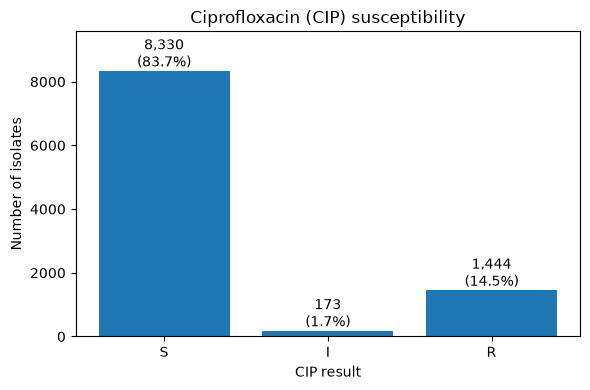

In [ ]:
cip_counts = bacteria_dataset["CIP"].value_counts().reindex(cip_values)
cip_pct = cip_counts / cip_counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cip_values, cip_counts.values)
for i, (n, p) in enumerate(zip(cip_counts, cip_pct)):
    ax.text(i, n, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, cip_counts.max() * 1.15)
ax.set_title("Ciprofloxacin (CIP) susceptibility")
ax.set_xlabel("CIP result")
ax.set_ylabel("Number of isolates")
plt.tight_layout()
plt.show()

### 5.2 CIP resistance by the result of each other antibiotic

For each antibiotic, the green dot is the % of CIP = R among isolates susceptible (S) to that antibiotic, and the blue dot among isolates resistant (R) to it. The longer the line between them, the more informative the antibiotic is as a predictor of CIP (the gap in percentage points is in the label). Isolates with an intermediate result (`I`) are not shown here because they are few (~170 per antibiotic) and their treatment will be decided in section 6.

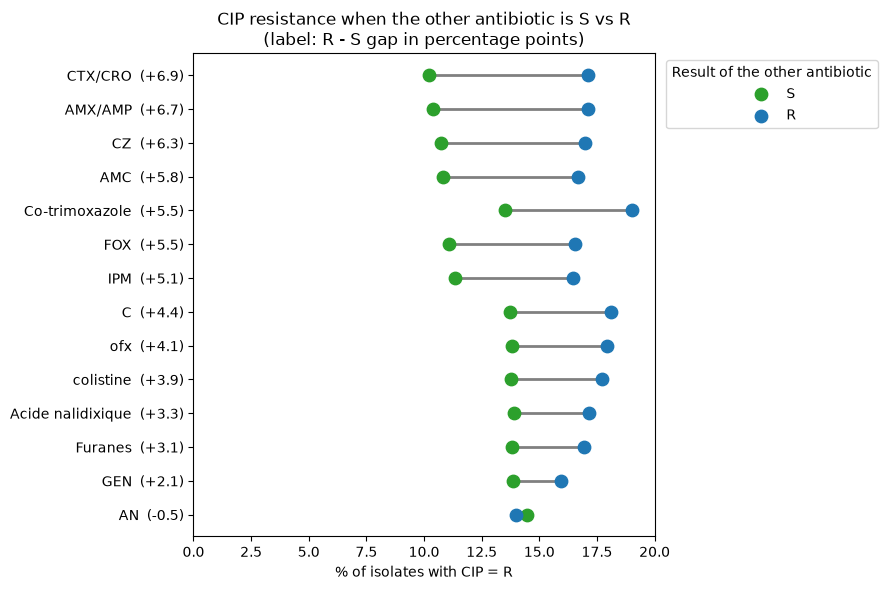

In [ ]:
rates = pd.DataFrame({
    ab: bacteria_dataset.groupby(ab)["CIP"].apply(lambda s: s.eq("R").mean() * 100)
    for ab in other_antibiotics
}).T.reindex(columns=cip_values)
rates["gap"] = rates["R"] - rates["S"]
rates = rates.sort_values("gap")  # largest gap ends up on top

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(rates))
ax.hlines(y, rates["S"], rates["R"], color="grey", lw=2, zorder=1)
ax.scatter(rates["S"], y, color="tab:green", s=80, label="S", zorder=2)
ax.scatter(rates["R"], y, color="tab:blue", s=80, label="R", zorder=2)

ax.set_yticks(y, [f"{ab}  ({gap:+.1f})" for ab, gap in rates["gap"].items()])
ax.set_xlabel("% of isolates with CIP = R")
ax.set_title("CIP resistance when the other antibiotic is S vs R\n(label: R - S gap in percentage points)")
ax.legend(title="Result of the other antibiotic", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xlim(0, 20)
plt.tight_layout()
plt.show()

### 5.3 CIP resistance by bacterial species

Each bar is the % of isolates of that species that are resistant to CIP (CIP = R). The dashed line is the overall rate. If the bars were all at the dashed line, the species would not help predict CIP; here they differ (see the chi-square p-value), so `Souches` is kept as a feature (one-hot encoded). *E. coli* is the highest and is also the most frequent species (n in the labels).

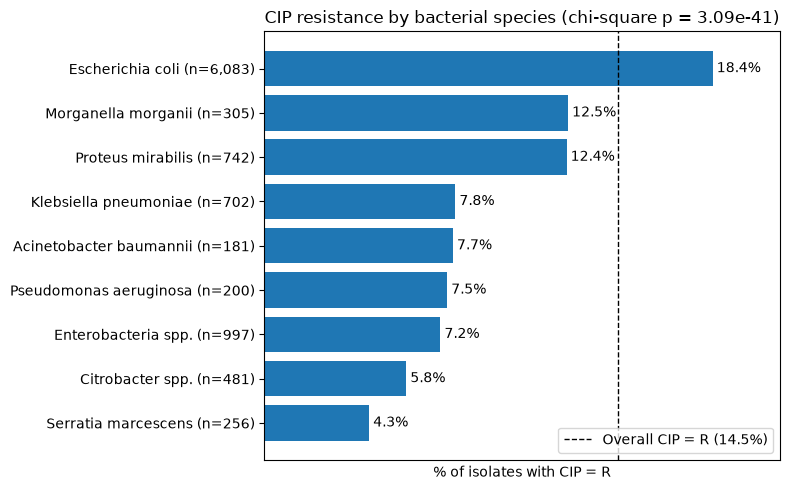

In [60]:
sub = bacteria_dataset[["Souches"]].assign(cip_r=cip_r).dropna()
rate = sub.groupby("Souches")["cip_r"].mean().mul(100).sort_values()
n_group = sub.groupby("Souches").size().reindex(rate.index)
p_value = stats.chi2_contingency(pd.crosstab(sub["Souches"], sub["cip_r"]))[1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"{s} (n={n_group[s]:,})" for s in rate.index], rate.values, color="tab:blue")
ax.axvline(cip_r.mean() * 100, color="black", ls="--", lw=1,
           label=f"Overall CIP = R ({cip_r.mean() * 100:.1f}%)")
for i, r in enumerate(rate):
    ax.text(r, i, f" {r:.1f}%", va="center")
ax.set_xlim(0, rate.max() * 1.15)
ax.set_xlabel("% of isolates with CIP = R")
ax.set_title(f"CIP resistance by bacterial species (chi-square p = {p_value:.3g})")
ax.legend(loc="lower right")
plt.xticks([])
plt.tight_layout()
plt.show()

** ESTO NOS AYUDA A EXPLICAR PORQUÉ LA ESPECIA DE BACTERIA ES UN BUEN PREDICTOR PARA EL MODELO.  explain here

### 5.4 Age by CIP result

Boxplot of `Age` for each CIP result, with the number of isolates and the median in the label. If the boxes and medians are similar across S, I and R, age carries little information about CIP. The whiskers also give a first look at outliers for section 7.

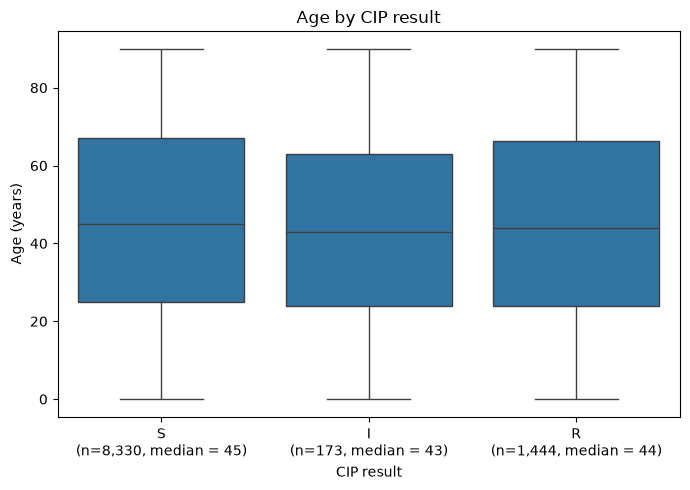

In [55]:
age_df = bacteria_dataset[["CIP", "Age"]].astype({"Age": float})
age_labels = [
    f"{c}\n(n={age_df['CIP'].eq(c).sum():,}, median = {age_df.loc[age_df['CIP'] == c, 'Age'].median():.0f})"
    for c in cip_values
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=age_df, x="CIP", y="Age", order=cip_values, ax=ax)
ax.set_xticks(range(len(cip_values)), age_labels)
ax.set_title("Age by CIP result")
ax.set_xlabel("CIP result")
ax.set_ylabel("Age (years)")
plt.tight_layout()
plt.show()

`Age` ranges from 0 to 90 with no outliers, and its distribution is roughly uniform rather than bell-shaped. It is similar across S, I and R, so it carries little information about CIP. (No outliers hablarlo)

### 5.5 CIP resistance by clinical variable

Each dot is the % of CIP = R in one category of a clinical variable, with the number of isolates in the label. The dashed line is the overall rate and the chi-square p-value of each variable is on the right. If the dots sit on the dashed line (high p-value), the variable does not separate resistant from susceptible isolates. Here all p-values are well above 0.05, so none of these variables shows evidence of a relationship with CIP.

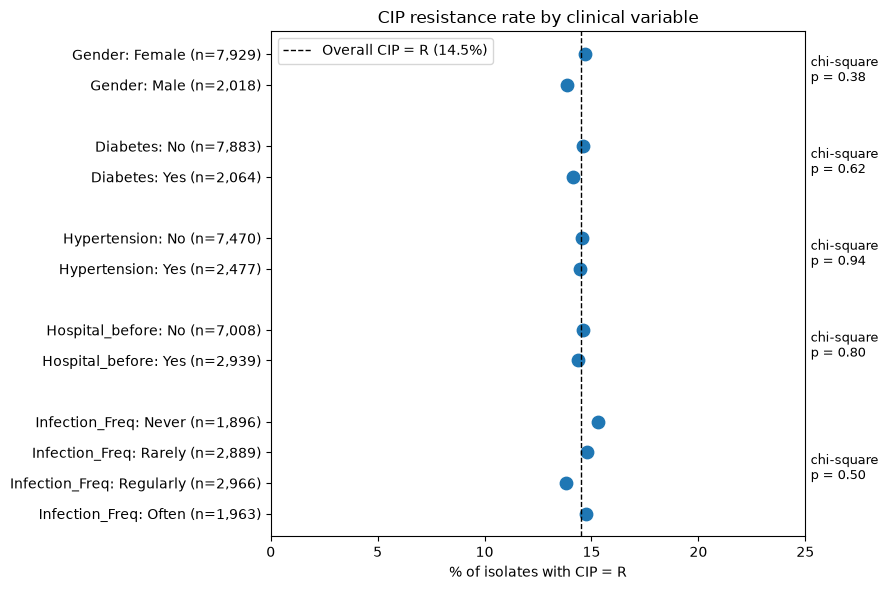

In [70]:
clinical_vars = {
    "Gender": {"F": "Female", "M": "Male"},
    "Diabetes": {0: "No", 1: "Yes"},
    "Hypertension": {0: "No", 1: "Yes"},
    "Hospital_before": {0: "No", 1: "Yes"},
    "Infection_Freq": {0: "Never", 1: "Rarely", 2: "Regularly", 3: "Often"},
}

fig, ax = plt.subplots(figsize=(9, 6))
y, labels_y, pos = [], [], 0
for var, labels in clinical_vars.items():
    sub = bacteria_dataset[[var]].assign(cip_r=cip_r)
    rate = sub.groupby(var)["cip_r"].mean() * 100
    n_group = sub.groupby(var).size()
    p_value = stats.chi2_contingency(pd.crosstab(sub[var], sub["cip_r"]))[1]

    group_pos = list(range(pos, pos + len(rate)))
    ax.scatter(rate.values, group_pos, color="tab:blue", s=80, zorder=2)
    for yi, (k, r) in zip(group_pos, rate.items()):
        labels_y.append(f"{var}: {labels[k]} (n={n_group[k]:,})")
    ax.text(1.01, np.mean(group_pos), f"chi-square\np = {p_value:.2f}", va="center",
            transform=ax.get_yaxis_transform(), fontsize=9)
    y += group_pos
    pos += len(rate) + 1  # blank row between variables

ax.axvline(cip_r.mean() * 100, color="black", ls="--", lw=1,
           label=f"Overall CIP = R ({cip_r.mean() * 100:.1f}%)")
ax.set_yticks(y, labels_y)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xlabel("% of isolates with CIP = R")
ax.set_title("CIP resistance rate by clinical variable")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The conclusion is simple and it is a valid result: Gender, Diabetes, Hypertension, Hospital_before and Infection_Freq have all p-values way above 0.05. Thus, these clinical variables report little information about CIP. (Talk about outliers here as well)

## 6. Target formulation: ciprofloxacin (CIP)

here decide what to do with CIP = I


aca tmb deberiamos cambiar todos los R, S a 1s y 0s? o no es necesario


## 7. Outliers

Values outside the expected pattern must be reviewed rather than silently treated as valid.

# **Conclusions**